# Упражнение: признаки изображений
Мы уже видели, что линейный классификатор, обученный на пикселях входного изображения, даёт вполне приемлемое качество в задаче классификации изображений. В этом упражнении мы покажем, что качество классификации можно повысить, если обучать линейные классификаторы не на исходных пикселях, а на признаках, вычисленных по этим пикселям.

Всю работу в этом упражнении вы выполняете прямо в этом ноутбуке.

In [1]:
# @title Настройка окружения (запустите эту ячейку первой)
# В Google Colab ячейка подключит ваш Google Диск и перейдёт в папку с лабораторной.
# При локальном запуске (Jupyter) ничего подключать не нужно: достаточно открыть
# ноутбук из папки лабораторной.

# Путь к папке лабораторной внутри «Моего диска», например 'DL/assignment1'.
# Если оставить пустым, папка будет найдена автоматически.
FOLDERNAME = ''  # @param {type:"string"}

import glob
import os
import sys

NOTEBOOK = 'features.ipynb'

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE_ROOT = '/content/drive/MyDrive'
    lab_dir = None
    if FOLDERNAME:
        lab_dir = os.path.join(DRIVE_ROOT, FOLDERNAME.strip('/'))
    else:
        # Ищем на Диске папку, в которой лежат этот ноутбук и пакет dlcv.
        for depth in range(5):
            pattern = os.path.join(DRIVE_ROOT, *['*'] * depth, 'dlcv', '__init__.py')
            found = [os.path.dirname(os.path.dirname(p)) for p in sorted(glob.glob(pattern))]
            found = [d for d in found if os.path.isfile(os.path.join(d, NOTEBOOK))]
            if found:
                # Если копий несколько, берём ту, где ноутбук менялся последним.
                found.sort(key=lambda d: os.path.getmtime(os.path.join(d, NOTEBOOK)),
                           reverse=True)
                lab_dir = found[0]
                if len(found) > 1:
                    print('Найдено несколько папок с лабораторной:', *found, sep='\n  ')
                    print('Используется', lab_dir, '(другую папку можно указать в FOLDERNAME)')
                break
    if lab_dir is None or not os.path.isdir(os.path.join(lab_dir, 'dlcv')):
        raise FileNotFoundError(
            'Не удалось найти папку с лабораторной на Google Диске. Укажите путь '
            'к ней в FOLDERNAME, например: FOLDERNAME = \'DL/assignment1\'')
    os.chdir(lab_dir)

if not os.path.isdir('dlcv'):
    raise FileNotFoundError(
        'В текущей папке нет пакета dlcv. Откройте ноутбук из папки лабораторной.')
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

# В Colab используется IPython 7.x, и на Python 3.12+ его расширение autoreload
# не загружается: ему нужен удалённый из Python модуль imp. Подставляем
# совместимую замену (расширению нужна только функция reload).
import IPython
if (sys.version_info >= (3, 12) and IPython.version_info[0] < 8
        and 'imp' not in sys.modules):
    import importlib
    import types
    sys.modules['imp'] = types.ModuleType('imp')
    sys.modules['imp'].reload = importlib.reload

from dlcv.data_utils import ensure_cifar10
ensure_cifar10()
print('Рабочая папка:', os.getcwd())

Mounted at /content/drive
Рабочая папка: /content/drive/MyDrive/assignment1


In [2]:
import random
import numpy as np
from dlcv.data_utils import load_CIFAR10
import matplotlib.pyplot as plt


%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0) # размер графиков по умолчанию
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

# автоматическая перезагрузка внешних модулей
# см. http://stackoverflow.com/questions/1907993/autoreload-of-modules-in-ipython
%load_ext autoreload
%autoreload 2

## Загрузка данных
Как и в предыдущих упражнениях, загрузим данные CIFAR-10 с диска.

In [4]:
from dlcv.features import color_histogram_hsv, hog_feature

def get_CIFAR10_data(num_training=49000, num_validation=1000, num_test=1000):
    # Загружаем исходные данные CIFAR-10
    cifar10_dir = 'dlcv/datasets/cifar-10-batches-py'

    # Удаляем старые переменные, чтобы данные не загружались в память повторно
    # (иначе памяти может не хватить)
    try:
       del X_train, y_train
       del X_test, y_test
       print('Ранее загруженные данные удалены.')
    except:
       pass

    X_train, y_train, X_test, y_test = load_CIFAR10(cifar10_dir)

    # Формируем подвыборки
    mask = list(range(num_training, num_training + num_validation))
    X_val = X_train[mask]
    y_val = y_train[mask]
    mask = list(range(num_training))
    X_train = X_train[mask]
    y_train = y_train[mask]
    mask = list(range(num_test))
    X_test = X_test[mask]
    y_test = y_test[mask]

    return X_train, y_train, X_val, y_val, X_test, y_test

X_train, y_train, X_val, y_val, X_test, y_test = get_CIFAR10_data()

## Извлечение признаков
Для каждого изображения вычислим гистограмму направленных градиентов (Histogram of Oriented Gradients, HOG), а также цветовую гистограмму по каналу тона (hue) в цветовом пространстве HSV. Итоговый вектор признаков изображения получим конкатенацией векторов признаков HOG и цветовой гистограммы.

Грубо говоря, HOG описывает текстуру изображения и не учитывает информацию о цвете, а цветовая гистограмма, наоборот, описывает цвет входного изображения и не учитывает текстуру. Поэтому можно ожидать, что вместе они сработают лучше, чем каждый по отдельности. Проверить это предположение самостоятельно — полезное упражнение для интересующихся.

Функции `hog_feature` и `color_histogram_hsv` принимают одно изображение и возвращают для него вектор признаков. Функция `extract_features` принимает набор изображений и список функций признаков, применяет каждую функцию к каждому изображению и сохраняет результаты в матрицу, каждая строка которой — конкатенация всех векторов признаков одного изображения.

In [5]:
from dlcv.features import *

# num_color_bins = 10 # Число бинов цветовой гистограммы
num_color_bins = 25 # Число бинов цветовой гистограммы
feature_fns = [hog_feature, lambda img: color_histogram_hsv(img, nbin=num_color_bins)]
X_train_feats = extract_features(X_train, feature_fns, verbose=True)
X_val_feats = extract_features(X_val, feature_fns)
X_test_feats = extract_features(X_test, feature_fns)

# Предобработка: вычитаем среднее значение каждого признака
mean_feat = np.mean(X_train_feats, axis=0, keepdims=True)
X_train_feats -= mean_feat
X_val_feats -= mean_feat
X_test_feats -= mean_feat

# Предобработка: делим на стандартное отклонение, чтобы все признаки
# имели примерно одинаковый масштаб.
std_feat = np.std(X_train_feats, axis=0, keepdims=True)
X_train_feats /= std_feat
X_val_feats /= std_feat
X_test_feats /= std_feat

# Предобработка: добавляем размерность для смещения (столбец из единиц)
X_train_feats = np.hstack([X_train_feats, np.ones((X_train_feats.shape[0], 1))])
X_val_feats = np.hstack([X_val_feats, np.ones((X_val_feats.shape[0], 1))])
X_test_feats = np.hstack([X_test_feats, np.ones((X_test_feats.shape[0], 1))])

Признаки извлечены для 1000 / 49000 изображений
Признаки извлечены для 2000 / 49000 изображений
Признаки извлечены для 3000 / 49000 изображений
Признаки извлечены для 4000 / 49000 изображений
Признаки извлечены для 5000 / 49000 изображений
Признаки извлечены для 6000 / 49000 изображений
Признаки извлечены для 7000 / 49000 изображений
Признаки извлечены для 8000 / 49000 изображений
Признаки извлечены для 9000 / 49000 изображений
Признаки извлечены для 10000 / 49000 изображений
Признаки извлечены для 11000 / 49000 изображений
Признаки извлечены для 12000 / 49000 изображений
Признаки извлечены для 13000 / 49000 изображений
Признаки извлечены для 14000 / 49000 изображений
Признаки извлечены для 15000 / 49000 изображений
Признаки извлечены для 16000 / 49000 изображений
Признаки извлечены для 17000 / 49000 изображений
Признаки извлечены для 18000 / 49000 изображений
Признаки извлечены для 19000 / 49000 изображений
Признаки извлечены для 20000 / 49000 изображений
Признаки извлечены для 21000 

## Обучение классификатора Softmax на признаках
С помощью кода Softmax, написанного ранее в этой лабораторной работе, обучите классификаторы Softmax на извлечённых выше признаках. Результат должен получиться лучше, чем при обучении непосредственно на исходных пикселях.

In [9]:
# Подберите скорость обучения и коэффициент регуляризации по валидационной выборке

from dlcv.classifiers.linear_classifier import Softmax

learning_rates = [1e-3, 1e-2, 1e-1]
regularization_strengths = [1e-3, 1e-2, 1e-1, 1.0]

results = {}
best_val = -1
best_softmax = None


for lr in learning_rates:
    for reg in regularization_strengths:
        softmax = Softmax()
        softmax.train(X_train_feats, y_train, learning_rate=lr, reg=reg, num_iters=1500, verbose=False)

        y_train_pred = softmax.predict(X_train_feats)
        train_acc = np.mean(y_train_pred == y_train)

        y_val_pred = softmax.predict(X_val_feats)
        val_acc = np.mean(y_val_pred == y_val)

        results[(lr, reg)] = (train_acc, val_acc)

        if val_acc > best_val:
            best_val = val_acc
            best_softmax = softmax

# Выводим результаты.
for lr, reg in sorted(results):
    train_accuracy, val_accuracy = results[(lr, reg)]
    print('lr %e reg %e точность на обучении: %f точность на валидации: %f' % (
                lr, reg, train_accuracy, val_accuracy))

print('лучшая достигнутая точность на валидационной выборке: %f' % best_val)

lr 1.000000e-03 reg 1.000000e-03 точность на обучении: 0.451980 точность на валидации: 0.451000
lr 1.000000e-03 reg 1.000000e-02 точность на обучении: 0.450082 точность на валидации: 0.460000
lr 1.000000e-03 reg 1.000000e-01 точность на обучении: 0.449939 точность на валидации: 0.455000
lr 1.000000e-03 reg 1.000000e+00 точность на обучении: 0.438020 точность на валидации: 0.447000
lr 1.000000e-02 reg 1.000000e-03 точность на обучении: 0.513265 точность на валидации: 0.498000
lr 1.000000e-02 reg 1.000000e-02 точность на обучении: 0.511612 точность на валидации: 0.502000
lr 1.000000e-02 reg 1.000000e-01 точность на обучении: 0.489653 точность на валидации: 0.487000
lr 1.000000e-02 reg 1.000000e+00 точность на обучении: 0.438490 точность на валидации: 0.435000
lr 1.000000e-01 reg 1.000000e-03 точность на обучении: 0.521612 точность на валидации: 0.517000
lr 1.000000e-01 reg 1.000000e-02 точность на обучении: 0.516776 точность на валидации: 0.511000
lr 1.000000e-01 reg 1.000000e-01 точност

In [10]:
# Оцените обученный Softmax на тестовой выборке: точность должна быть не ниже 0.42
y_test_pred = best_softmax.predict(X_test_feats)
test_accuracy = np.mean(y_test == y_test_pred)
print(test_accuracy)

0.497


In [11]:
# Сохраняем лучшую модель Softmax (файл появится в папке `dlcv/saved/`)
best_softmax.save("best_softmax_features.npy")

best_softmax_features.npy сохранён.


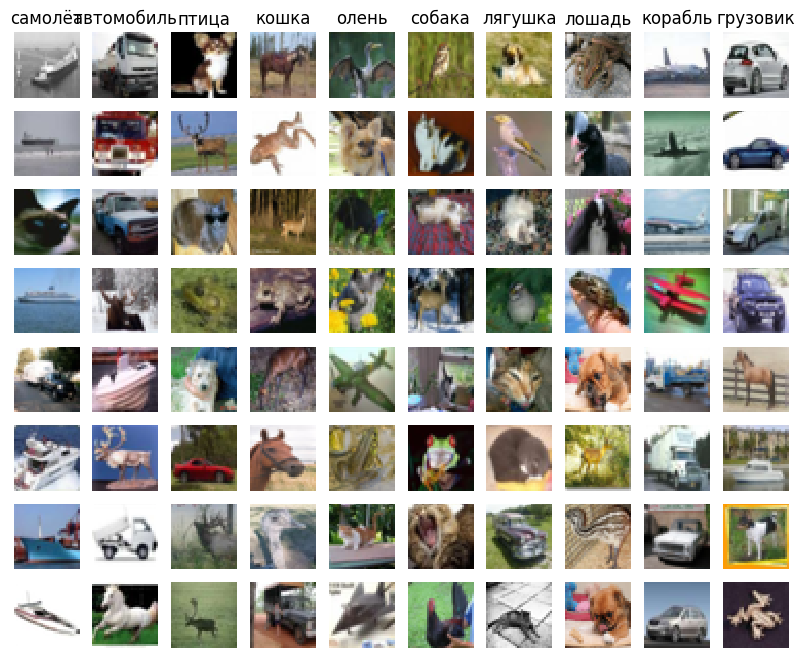

In [12]:
# Хороший способ интуитивно понять, как работает алгоритм, — посмотреть
# на ошибки, которые он совершает. Ниже показаны примеры изображений,
# которые текущая модель классифицировала неверно. В первом столбце —
# изображения, которым модель присвоила метку «самолёт», хотя на самом деле
# их истинная метка другая.

examples_per_class = 8
classes = ['самолёт', 'автомобиль', 'птица', 'кошка', 'олень', 'собака', 'лягушка', 'лошадь', 'корабль', 'грузовик']
for cls, cls_name in enumerate(classes):
    idxs = np.where((y_test != cls) & (y_test_pred == cls))[0]
    idxs = np.random.choice(idxs, examples_per_class, replace=False)
    for i, idx in enumerate(idxs):
        plt.subplot(examples_per_class, len(classes), i * len(classes) + cls + 1)
        plt.imshow(X_test[idx].astype('uint8'))
        plt.axis('off')
        if i == 0:
            plt.title(cls_name)
plt.show()

### Вопрос 1
Опишите ошибки классификации, которые вы видите. Можно ли найти им разумное объяснение?

**Ваш ответ:** *Скорее всего признаки HOG, HUE являются слишком грубыми: передают общие очертания и цветовую гамму, но теряют мелкие детали. Поэтому модель путает визуально схожие классы (кошка/собака, автомобиль/грузовик), т.к. их силуэты и цветовые профили близки*


## Нейронная сеть на признаках изображений
Ранее в этой лабораторной работе мы видели, что двухслойная нейронная сеть, обученная на исходных пикселях, классифицирует изображения лучше, чем линейные классификаторы на тех же пикселях. В этом ноутбуке мы убедились, что линейные классификаторы на признаках изображений превосходят линейные классификаторы на исходных пикселях.

Для полноты картины стоит также обучить нейронную сеть на признаках изображений. Этот подход должен превзойти все предыдущие: точность классификации на тестовой выборке выше 55% достигается без особого труда, а хорошо настроенная модель достигает 58–60%.

In [13]:
# Предобработка: удаляем размерность для смещения
# Обязательно запускайте эту ячейку только ОДИН раз
print(X_train_feats.shape)
X_train_feats = X_train_feats[:, :-1]
X_val_feats = X_val_feats[:, :-1]
X_test_feats = X_test_feats[:, :-1]

print(X_train_feats.shape)

(49000, 170)
(49000, 169)


In [23]:
from dlcv.classifiers.fc_net import TwoLayerNet
from dlcv.solver import Solver

input_dim = X_train_feats.shape[1]
hidden_dim = 500
num_classes = 10

learning_rates = [0.1, 0.15, 0.2]
regularization_strengths = [0.01, 0.1]
batch_size = 256
num_epochs = 10

data = {
    'X_train': X_train_feats,
    'y_train': y_train,
    'X_val': X_val_feats,
    'y_val': y_val,
    'X_test': X_test_feats,
    'y_test': y_test,
}

best_val_acc = 0.0
best_net = None
best_params = {}

for lr in learning_rates:
    for reg in regularization_strengths:
        print(f'Обучение: lr={lr}, reg={reg}')

        net = TwoLayerNet(input_dim, hidden_dim, num_classes, reg=reg)
        solver = Solver(
            net, data,
            update_rule='sgd',
            optim_config={'learning_rate': lr},
            lr_decay=0.95,
            num_epochs=num_epochs,
            batch_size=batch_size,
            print_every=500,
            verbose=False
        )
        solver.train()

        val_acc = solver.best_val_acc
        print(f'Val acc: {val_acc:.4f}\n')

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_net = net
            best_params = {'lr': lr, 'reg': reg, 'batch_size': batch_size}

print(f'\nЛучшая модель: {best_params}, val_acc={best_val_acc:.4f}')
test_acc = (best_net.loss(data["X_test"]).argmax(axis=1) == data["y_test"]).mean()
print(f'Test accuracy: {test_acc:.4f}')

Обучение: lr=0.1, reg=0.001
Val acc: 0.5530

Обучение: lr=0.1, reg=0.1
Val acc: 0.4620

Обучение: lr=0.15, reg=0.001
Val acc: 0.5800

Обучение: lr=0.15, reg=0.1
Val acc: 0.4590

Обучение: lr=0.2, reg=0.001
Val acc: 0.5910

Обучение: lr=0.2, reg=0.1
Val acc: 0.4570


Лучшая модель: {'lr': 0.2, 'reg': 0.001, 'batch_size': 256}, val_acc=0.5910
Test accuracy: 0.5640


In [24]:
# Оцените лучший классификатор на основе нейронной сети на тестовой
# выборке. Точность должна получиться выше 55%, а при тщательной настройке
# можно добиться 58–60% и более.

#ПОЛУЧИЛИ 0.59 НА ВАЛИДАЦИИ ПРИ УВЕЛИЧЕНИИ lr ДО 0.15!
#0.56 на тесте
y_test_pred = np.argmax(best_net.loss(data['X_test']), axis=1)
test_acc = (y_test_pred == data['y_test']).mean()
print(test_acc)

0.564


In [25]:
# Сохраняем лучшую модель (файл появится в папке `dlcv/saved/`)
best_net.save("best_two_layer_net_features.npy")

best_two_layer_net_features.npy сохранён.
